#библиотеки

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


#1

In [ ]:
p = pd.read_excel('/content/drive/MyDrive/nn fin/ML0.1 intro/Вариант 1.xlsx', header=2)
p = p.iloc[:-1,:]
p

,№,№ школы,Класс,Пол,Номер варианта,Задания с кратким ответом,Задания с развёрнутым ответом,Устная часть,Первичный балл,Балл,Минимальный балл
0,1.0,117.0,11,М,341.0,1+++--1+-++---0---------0,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,8.0,20.0,24.0
1,2.0,148.0,12А,М,338.0,1+---+0--+---+0----++-+-0,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,8.0,20.0,24.0
2,3.0,152.0,13,Ж,104.0,2-----0--+----1---------1,0(1)0(3)0(1)0(3)0(2)0(2)0(3)1(3)0(2)1(2)1(1)1(1),NaN,9.0,22.0,24.0
3,4.0,152.0,13,М,104.0,1+--+-0++-----2----++---0,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,9.0,22.0,24.0
4,5.0,132.0,11,М,337.0,1++---0-+++---1----+----2,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,10.0,24.0,24.0
...,...,...,...,...,...,...,...,...,...,...,...
3043,3044.0,146.0,11,Ж,338.0,2+++++5+++++++2+++++++++4,1(1)3(3)1(1)3(3)2(2)2(2)3(3)3(3)2(2)2(2)1(1)1(1),NaN,58.0,100.0,24.0
3044,3045.0,147.0,11,Ж,340.0,2+++++5+++++++2+++++++++4,1(1)3(3)1(1)3(3)2(2)2(2)3(3)3(3)2(2)2(2)1(1)1(1),NaN,58.0,100.0,24.0
3045,3046.0,147.0,11,Ж,338.0,2+++++5+++++++2+++++++++4,1(1)3(3)1(1)3(3)2(2)2(2)3(3)3(3)2(2)2(2)1(1)1(1),NaN,58.0,100.0,24.0
3046,3047.0,147.0,11,Ж,337.0,2+++++5+++++++2+++++++++4,1(1)3(3)1(1)3(3)2(2)2(2)3(3)3(3)2(2)2(2)1(1)1(1),NaN,58.0,100.0,24.0


#2

In [ ]:
p.describe()

,№,№ школы,Номер варианта,Первичный балл,Балл,Минимальный балл
count,3048.000000,3048.000000,3048.000000,3048.000000,3048.000000,3048.0
mean,1524.500000,138.753281,340.787730,43.573491,72.769029,24.0
std,880.026136,41.793413,39.077186,8.931816,13.664908,0.0
min,1.000000,104.000000,101.000000,8.000000,20.000000,24.0
25%,762.750000,126.000000,339.000000,38.000000,64.000000,24.0
50%,1524.500000,144.000000,342.000000,45.000000,72.000000,24.0
75%,2286.250000,148.000000,346.000000,50.000000,82.000000,24.0
max,3048.000000,1106.000000,706.000000,58.000000,100.000000,24.0


#3

In [ ]:
p['Балл'].mean()

72.76902887139107

In [ ]:
p[p['Балл'] < p['Балл'].mean()].shape[0] / p.shape[0] *100

51.27952755905512

#4

In [ ]:
p[p['Балл'] < p['Минимальный балл'].iloc[0]].shape[0]

4

In [ ]:
p[p['Балл'] < p['Минимальный балл'].iloc[0]].shape[0] / p.shape[0] *100

0.13123359580052493

#5

([<matplotlib.patches.Wedge at 0x792d15db1930>,
 [Text(1.0999906512860012, 0.004535094640576347, ''),
  Text(-1.0999906509940822, -0.0045351654452093085, '')])

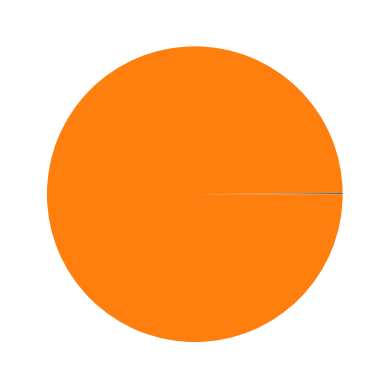

In [ ]:
a = p[p['Балл'] < p['Минимальный балл'].iloc[0]].shape[0]
b = p.shape[0] - a
plt.pie([a,b])

#6

<Axes: xlabel='Балл', ylabel='Density'>

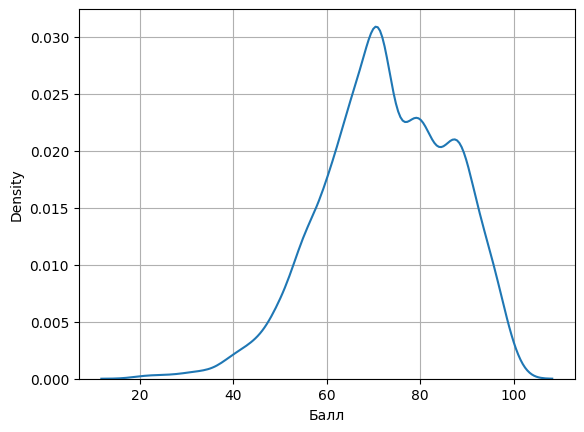

In [ ]:
plt.grid('ON')
seaborn.kdeplot(p['Балл'])

#7

In [ ]:
def Rating(x):
  if (x>=86):
    return 'Отлично'
  if (x>=71):
    return 'Хорошо'
  if (x>=51):
    return 'Удовлетворительно'

  return 'Неудовлетворительно'

p['Оценка'] = p['Балл'].apply(Rating)

In [ ]:
r = ['Отлично','Хорошо','Удовлетворительно','Неудовлетворительно']
rating_num = [p[p['Оценка'] == i].shape[0] for i in r]
display(rating_num)
print(*[(j,round(i/p.shape[0]*100,2)) for i,j in zip(rating_num,r)],sep='\n')

[618, 1124, 1134, 172]

('Отлично', 20.28)
('Хорошо', 36.88)
('Удовлетворительно', 37.2)
('Неудовлетворительно', 5.64)


#8

In [ ]:
p.groupby('Пол').agg('count').iloc[:,0]*100/p.shape[0]

,№
Пол,
Ж,57.972441
М,42.027559


#9

In [ ]:
p['№ школы'].unique().shape[0]

24

#10

In [ ]:
short_ans = len(p['Задания с кратким ответом'].iloc[0])
long_ans = len(p['Задания с развёрнутым ответом'].iloc[0])//4
short_ans,long_ans

(25, 12)

#11

In [ ]:
p.head()

,№,№ школы,Класс,Пол,Номер варианта,Задания с кратким ответом,Задания с развёрнутым ответом,Устная часть,Первичный балл,Балл,Минимальный балл,Оценка
0,1.0,117.0,11,М,341.0,1+++--1+-++---0---------0,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,8.0,20.0,24.0,Неудовлетворительно
1,2.0,148.0,12А,М,338.0,1+---+0--+---+0----++-+-0,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,8.0,20.0,24.0,Неудовлетворительно
2,3.0,152.0,13,Ж,104.0,2-----0--+----1---------1,0(1)0(3)0(1)0(3)0(2)0(2)0(3)1(3)0(2)1(2)1(1)1(1),NaN,9.0,22.0,24.0,Неудовлетворительно
3,4.0,152.0,13,М,104.0,1+--+-0++-----2----++---0,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,9.0,22.0,24.0,Неудовлетворительно
4,5.0,132.0,11,М,337.0,1++---0-+++---1----+----2,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1),NaN,10.0,24.0,24.0,Неудовлетворительно


In [ ]:
#B=pd.DataFrame.from_dict(dict([(f'B{i}',[0])for i in range(25)]),orient='index')
B = np.zeros(25,dtype=np.int64)
def B_create(x):
  x=x.replace("+","1").replace("-","0")
  for i in range(1,6):
    x=x.replace(f'{i}',"1")
  x=np.array(list(map(int,list(x))))
  return x

for i in p['Задания с кратким ответом'].apply(B_create).values:
  B+=i
B=B/p.shape[0]*100
B

array([98.68766404, 92.88057743, 87.33595801, 77.29658793, 58.95669291,
       90.6167979 , 95.04593176, 75.59055118, 84.12073491, 96.8832021 ,
       93.17585302, 75.52493438, 83.13648294, 70.17716535, 97.60498688,
       68.96325459, 67.22440945, 74.17979003, 69.35695538, 82.74278215,
       71.8503937 , 48.06430446, 76.54199475, 24.77034121, 95.43963255])

In [ ]:
print(*zip(np.arange(25)+1,B),sep='\n')

(1, 98.68766404199475)
(2, 92.88057742782152)
(3, 87.33595800524935)
(4, 77.29658792650919)
(5, 58.95669291338582)
(6, 90.61679790026247)
(7, 95.04593175853019)
(8, 75.59055118110236)
(9, 84.12073490813648)
(10, 96.88320209973753)
(11, 93.1758530183727)
(12, 75.52493438320211)
(13, 83.13648293963254)
(14, 70.17716535433071)
(15, 97.60498687664042)
(16, 68.96325459317585)
(17, 67.2244094488189)
(18, 74.17979002624672)
(19, 69.35695538057742)
(20, 82.74278215223097)
(21, 71.8503937007874)
(22, 48.06430446194226)
(23, 76.54199475065617)
(24, 24.77034120734908)
(25, 95.43963254593176)


#12

In [ ]:
def C_create(x):
  x=x.replace(')',' ').split(' ')[:-1]
  c=[]
  #print(x)
  for i in x:
    c.append(1 if i[0]==i[-1] else 0)
  return np.array(c)
C=np.zeros(long_ans)
for i in p['Задания с развёрнутым ответом'].apply(C_create).values:
  C+=i
C=C/p.shape[0]*100
C

array([96.7519685 , 47.50656168, 94.45538058, 61.35170604, 67.29002625,
       25.68897638, 41.33858268, 22.90026247, 32.05380577, 22.27690289,
       97.99868766, 84.54724409])

In [ ]:
print(*zip(np.arange(long_ans)+1,C),sep='\n')

(1, 96.75196850393701)
(2, 47.506561679790025)
(3, 94.45538057742782)
(4, 61.3517060367454)
(5, 67.29002624671917)
(6, 25.688976377952756)
(7, 41.338582677165356)
(8, 22.900262467191602)
(9, 32.05380577427822)
(10, 22.27690288713911)
(11, 97.998687664042)
(12, 84.54724409448819)


#13

In [ ]:
p['B'] = p['Задания с кратким ответом'].apply(B_create)
p['C'] = p['Задания с развёрнутым ответом'].apply(C_create)

In [ ]:
p.iloc[0]

,0
№,1.0
№ школы,117.0
Класс,11
Пол,М
Номер варианта,341.0
Задания с кратким ответом,1+++--1+-++---0---------0
Задания с развёрнутым ответом,0(1)0(3)0(1)0(3)0(2)0(2)0(3)0(3)0(2)0(2)0(1)0(1)
Устная часть,NaN
Первичный балл,8.0
Балл,20.0


##1

In [ ]:
def meaner(x):
  #print(x)
  return np.mean(x.values)
p1 = p.groupby('№ школы')['B'].agg('mean').iloc[:2]
n = '\n'
print(f"mean of completed tasks by school number {p1.index[0]} is:",*zip(np.arange(1,26),p1.iloc[0]),sep='\n')
print()
print(f"mean of completed tasks by school number {p1.index[1]} is:",*zip(np.arange(1,26),p1.iloc[1]),sep='\n')

mean of completed tasks by school number 104.0 is:
(1, 0.978021978021978)
(2, 0.9010989010989011)
(3, 0.8131868131868132)
(4, 0.8021978021978022)
(5, 0.5604395604395604)
(6, 0.8791208791208791)
(7, 0.989010989010989)
(8, 0.8131868131868132)
(9, 0.9230769230769231)
(10, 0.978021978021978)
(11, 0.8791208791208791)
(12, 0.7912087912087912)
(13, 0.8681318681318682)
(14, 0.7252747252747253)
(15, 0.967032967032967)
(16, 0.7252747252747253)
(17, 0.6483516483516484)
(18, 0.7142857142857143)
(19, 0.7142857142857143)
(20, 0.8131868131868132)
(21, 0.7252747252747253)
(22, 0.4065934065934066)
(23, 0.7362637362637363)
(24, 0.1978021978021978)
(25, 0.989010989010989)

mean of completed tasks by school number 108.0 is:
(1, 1.0)
(2, 0.9230769230769231)
(3, 0.8717948717948718)
(4, 0.7948717948717948)
(5, 0.5641025641025641)
(6, 0.8205128205128205)
(7, 0.9743589743589743)
(8, 0.6666666666666666)
(9, 0.8461538461538461)
(10, 1.0)
(11, 0.9487179487179487)
(12, 0.7692307692307693)
(13, 0.8205128205128205)


##2

In [ ]:
def Checker(x):
  #return np.mean(x.apply(np.sum)/long_ans)
  return x.mean()
p1 = p.groupby('№ школы')['C'].agg(Checker).iloc[:2]
p1

,C
№ школы,
104.0,"[1.0, 0.5494505494505495, 0.978021978021978, 0..."
108.0,"[1.0, 0.41025641025641024, 1.0, 0.641025641025..."


In [ ]:
p1.iloc[0].shape

(91,)

In [ ]:
print(f"mean of completed tasks by school number {p1.index[0]} is:",*zip(np.arange(1,26),p1.iloc[0]),sep='\n')
print()
print(f"mean of completed tasks by school number {p1.index[1]} is:",*zip(np.arange(1,26),p1.iloc[1]),sep='\n')

mean of completed tasks by school number 104.0 is:
(1, 1.0)
(2, 0.5494505494505495)
(3, 0.978021978021978)
(4, 0.7032967032967034)
(5, 0.7472527472527473)
(6, 0.24175824175824176)
(7, 0.4835164835164835)
(8, 0.21978021978021978)
(9, 0.37362637362637363)
(10, 0.18681318681318682)
(11, 0.989010989010989)
(12, 0.8241758241758241)

mean of completed tasks by school number 108.0 is:
(1, 1.0)
(2, 0.41025641025641024)
(3, 1.0)
(4, 0.6410256410256411)
(5, 0.7435897435897436)
(6, 0.3333333333333333)
(7, 0.38461538461538464)
(8, 0.1794871794871795)
(9, 0.28205128205128205)
(10, 0.2564102564102564)
(11, 1.0)
(12, 0.9230769230769231)


##3

In [ ]:
#p[p['№ школы'].isin(p['№ школы'].iloc[:2].values)]

In [ ]:
#p1 = p[p['№ школы'].isin(p['№ школы'].iloc[:2].values)].groupby('Пол')['Балл'].agg('mean')
p1 = p.groupby(['№ школы','Пол'])['Балл'].agg('mean').iloc[:4]
p1

№ школы  Пол
104.0    Ж      73.825397
         М      74.714286
108.0    Ж      78.500000
         М      64.800000
Name: Балл, dtype: float64

#14